# Complete Controlled Comparison: 2024 Phishing Framework vs Baseline Models

**Paper:** Al-Subaiey, Al-Thani, Alam, Antora, Khandakar & Uz Zaman (2024). *Novel Interpretable and Robust Web-based AI Platform for Phishing Email Detection.* Computers and Electrical Engineering, 120, 109625.

**Goal:** Reproduce the paper's own controlled protocol on the same merged Kaggle dataset:

1. **TF-IDF features** feeding three classifiers used in the paper: Multinomial Naive Bayes, Random Forest (100 trees), and a linear-kernel SVC (the paper's best / "proposed" model).
2. A same-split, same-preprocessing comparison across the three models.
3. **LIME** explainability on the winning model, matching the paper's XAI component.
4. A literature-comparison table against the paper's reported Table 2 values.

---

In [11]:
!pip -q install -U scikit-learn pandas matplotlib scipy statsmodels nltk gensim lime kagglehub

## 0. Runtime
In Google Colab select **Runtime -> Change runtime type -> CPU is enough** (this notebook is scikit-learn based, not deep learning; a GPU is not required).

In [12]:
# Install dependencies first using requirements.txt
# !pip -q install -U scikit-learn pandas matplotlib scipy statsmodels nltk gensim lime kagglehub

In [13]:
import os, gc, json, time, re, string, random, shutil, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              confusion_matrix, ConfusionMatrixDisplay, classification_report)
from statsmodels.stats.contingency_tables import mcnemar

warnings.filterwarnings('ignore')
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
print('Setup complete. Seed:', SEED)

Setup complete. Seed: 42


## 1. Configuration
These settings define the paper's own 80/20 protocol plus a few controlled-comparison choices we make explicit (max TF-IDF features, RF tree count, LIME feature count).

In [14]:
PROJECT_DIR = Path('/content/phishing_2024_project')
DATA_DIR = PROJECT_DIR / 'data'
RESULTS_DIR = PROJECT_DIR / 'results'
for d in [DATA_DIR, RESULTS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# The 2024 paper's own controlled protocol: 80/20 train/test split, TF-IDF vectorizer,
# SVC (linear kernel), Multinomial Naive Bayes, and a 100-tree Random Forest, all with
# random_state = 42. The paper does not report a fixed validation split, so we add one
# small validation carve-out (10% of train) ONLY for our own diagnostics; it plays no
# role in the headline paper-comparison numbers, which use the paper's 80/20 protocol.
TEST_SIZE = 0.20
MAX_TFIDF_FEATURES = 40000
RF_TREES = 100
LIME_NUM_FEATURES = 10
RUN_WORD2VEC_ABLATION = False  # optional, slower; reproduces the paper's tf-idf vs word2vec finding

print('Config loaded')

Config loaded


## 2. Download the same merged dataset identified by the 2024 paper
Kaggle dataset: **naserabdullahalam/phishing-email-dataset** (Enron + Ling + CEAS + Nazario + Nigerian Fraud + SpamAssassin, ~82,486 emails).

In [15]:
# Same dataset identified by the 2024 paper: a merge of Enron, Ling, CEAS, Nazario,
# Nigerian Fraud and SpamAssassin (~82,486 emails; 42,891 phishing / 39,595 legitimate).
import kagglehub
try:
    path = kagglehub.dataset_download('naserabdullahalam/phishing-email-dataset', output_dir=str(DATA_DIR))
    print('Downloaded to:', path)
except Exception as e:
    print('Automatic download failed:', e)
    print('Fallback: download manually from '
          'https://www.kaggle.com/datasets/naserabdullahalam/phishing-email-dataset '
          'and place the CSV(s) into /content/phishing_2024_project/data/')

100%|██████████| 77.1M/77.1M [00:01<00:00, 73.4MB/s]

Extracting files...


Downloaded to: /content/phishing_2024_project/data


In [16]:
csv_files = list(DATA_DIR.rglob('*.csv'))
print('CSV files found:', csv_files)
if not csv_files:
    raise FileNotFoundError('No CSV found. Upload the Kaggle CSV(s) into '
                             '/content/phishing_2024_project/data/ and rerun this cell.')
# The dataset ships one merged file (commonly named phishing_email.csv with a
# pre-combined 'text_combined' column) plus several per-source CSVs. Prefer the
# largest merged file, matching the paper's merged mdf_1/mdf_2 -> final dataset step.
CSV_PATH = max(csv_files, key=lambda p: p.stat().st_size)
df_raw = pd.read_csv(CSV_PATH)
print('Selected file:', CSV_PATH)
print('Original shape:', df_raw.shape)
print('Columns:', df_raw.columns.tolist())
display(df_raw.head())

CSV files found: [PosixPath('/content/phishing_2024_project/data/Nazario.csv'), PosixPath('/content/phishing_2024_project/data/Enron.csv'), PosixPath('/content/phishing_2024_project/data/Nigerian_Fraud.csv'), PosixPath('/content/phishing_2024_project/data/SpamAssasin.csv'), PosixPath('/content/phishing_2024_project/data/CEAS_08.csv'), PosixPath('/content/phishing_2024_project/data/Ling.csv'), PosixPath('/content/phishing_2024_project/data/phishing_email.csv')]
Selected file: /content/phishing_2024_project/data/phishing_email.csv
Original shape: (82486, 2)
Columns: ['text_combined', 'label']


,text_combined,label
0,hpl nom may 25 2001 see attached file hplno 52...,0
1,nom actual vols 24 th forwarded sabrae zajac h...,0
2,enron actuals march 30 april 1 201 estimated a...,0
3,hpl nom may 30 2001 see attached file hplno 53...,0
4,hpl nom june 1 2001 see attached file hplno 60...,0


## 3. Dataset audit: identify text/label columns and build text_combined if needed

In [17]:
def find_col(cols, candidates):
    m = {str(c).strip().lower(): c for c in cols}
    for cand in candidates:
        if cand.lower() in m:
            return m[cand.lower()]
    return None

TEXT_COL = find_col(df_raw.columns, ['text_combined', 'text', 'body', 'email text', 'message'])
LABEL_COL = find_col(df_raw.columns, ['label', 'email type', 'class', 'type'])
SUBJECT_COL = find_col(df_raw.columns, ['subject'])
BODY_COL = find_col(df_raw.columns, ['body'])

if LABEL_COL is None:
    raise ValueError(f'Could not identify the label column. Available: {df_raw.columns.tolist()}')

# The paper's key finding is that merging subject + body (+ sender/date where present)
# into one 'text_combined' field materially improves performance (F1 0.71 -> 0.82 under
# word2vec). If the Kaggle file does not already ship a merged column, build one here.
if TEXT_COL is None:
    parts = [c for c in [SUBJECT_COL, BODY_COL] if c is not None]
    if not parts:
        raise ValueError('Could not find a usable text column. '
                          f'Available columns: {df_raw.columns.tolist()}')
    df_raw['text_combined'] = df_raw[parts].astype(str).agg(' '.join, axis=1)
    TEXT_COL = 'text_combined'

print('Text column:', TEXT_COL)
print('Label column:', LABEL_COL)
print('\nOriginal label distribution:')
print(df_raw[LABEL_COL].value_counts(dropna=False))
print('\nMissing values:')
print(df_raw[[TEXT_COL, LABEL_COL]].isna().sum())
print('Exact duplicate rows:', df_raw.duplicated().sum())
print('Duplicate texts:', df_raw.duplicated(subset=[TEXT_COL]).sum())

Text column: text_combined
Label column: label

Original label distribution:
label
1    42891
0    39595
Name: count, dtype: int64

Missing values:
text_combined    0
label            0
dtype: int64
Exact duplicate rows: 408
Duplicate texts: 408


## 4. Map labels to a binary Legitimate (0) / Phishing (1) target

In [18]:
def map_label(v):
    s = str(v).strip().lower()
    if s in {'1', 'phishing', 'spam', 'phish'}:
        return 1
    if s in {'0', 'legitimate', 'ham', 'safe'}:
        return 0
    try:
        return int(float(s))
    except ValueError:
        return np.nan

df = df_raw[[TEXT_COL, LABEL_COL]].copy()
df.columns = ['text', 'label_original']
original_n = len(df)
df = df.dropna(subset=['text', 'label_original']).copy()
df['label'] = df['label_original'].map(map_label)
if df['label'].isna().any():
    print('Unmapped labels found:')
    print(df.loc[df['label'].isna(), 'label_original'].value_counts())
    df = df.dropna(subset=['label']).copy()
df['label'] = df['label'].astype(int)

## 5. Clean text, remove duplicates, and summarise the dataset

In [19]:
# Text cleaning: tokenization-friendly lowercasing, punctuation removal, whitespace
# normalization. Stop-word removal happens inside TfidfVectorizer(stop_words='english')
# so the raw cleaned text is retained for inspection and for LIME explanations.
PUNCT_TABLE = str.maketrans('', '', string.punctuation)

def clean_text(t):
    t = str(t).lower()
    t = re.sub(r'http\S+|www\.\S+', ' url ', t)
    t = t.translate(PUNCT_TABLE)
    t = re.sub(r'\s+', ' ', t).strip()
    return t

df['text'] = df['text'].map(clean_text)
df = df[df['text'].str.len() > 0].copy()
after_empty_n = len(df)
before_dupe = len(df)
df = df.drop_duplicates(subset=['text']).copy()
removed_dupes = before_dupe - len(df)
df['word_count'] = df['text'].str.split().str.len()
df = df.reset_index(drop=True)

summary = pd.DataFrame({
    'item': ['original_records', 'after_empty_removal', 'duplicates_removed', 'final_records',
             'legitimate_emails', 'phishing_emails', 'mean_word_count', 'median_word_count', 'max_word_count'],
    'value': [original_n, after_empty_n, removed_dupes, len(df),
              int((df.label == 0).sum()), int((df.label == 1).sum()),
              round(df.word_count.mean(), 2), round(df.word_count.median(), 2), int(df.word_count.max())]
})
display(summary)
summary.to_csv(RESULTS_DIR / 'dataset_summary.csv', index=False)

,item,value
0,original_records,82486.00
1,after_empty_removal,82485.00
2,duplicates_removed,417.00
3,final_records,82068.00
4,legitimate_emails,39233.00
5,phishing_emails,42835.00
6,mean_word_count,159.01
7,median_word_count,78.00
8,max_word_count,107716.00


## 6. Exploratory plots: class balance and email length

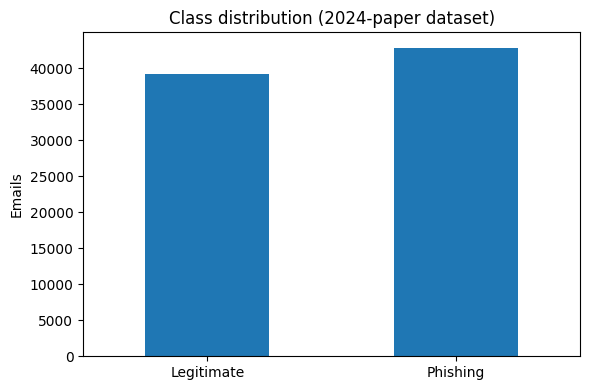

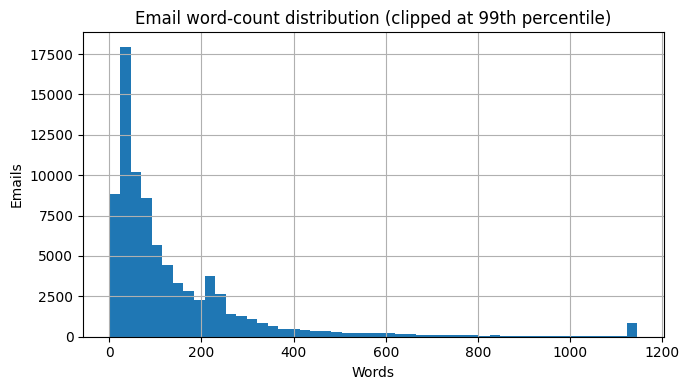

In [20]:
counts = df['label'].value_counts().sort_index()
plt.figure(figsize=(6, 4))
counts.index = ['Legitimate', 'Phishing']
counts.plot(kind='bar')
plt.title('Class distribution (2024-paper dataset)')
plt.ylabel('Emails')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'class_distribution.png', dpi=300)
plt.show()

plt.figure(figsize=(7, 4))
df['word_count'].clip(upper=df['word_count'].quantile(.99)).hist(bins=50)
plt.title('Email word-count distribution (clipped at 99th percentile)')
plt.xlabel('Words')
plt.ylabel('Emails')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'length_distribution.png', dpi=300)
plt.show()

## 7. Fixed 80/20 train/test split (the paper's own protocol, seed 42)

In [21]:
# Paper's own protocol: single stratified 80/20 train/test split, seed 42.
train_df, test_df = train_test_split(df[['text', 'label']], test_size=TEST_SIZE,
                                      stratify=df['label'], random_state=SEED)
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)
print('Train / Test:', len(train_df), len(test_df))
print('Test class counts:\n', test_df.label.value_counts().sort_index())
train_df.to_csv(DATA_DIR / 'train.csv', index=False)
test_df.to_csv(DATA_DIR / 'test.csv', index=False)

Train / Test: 65654 16414
Test class counts:
 label
0    7847
1    8567
Name: count, dtype: int64


## 8. Shared train / evaluate helper

In [22]:
def metrics_from_preds(y_true, y_pred):
    return {
        'accuracy': float(accuracy_score(y_true, y_pred)),
        'precision': float(precision_score(y_true, y_pred, zero_division=0)),
        'recall': float(recall_score(y_true, y_pred, zero_division=0)),
        'f1': float(f1_score(y_true, y_pred, zero_division=0)),
    }

def train_and_eval(name, pipeline, train_df, test_df):
    start = time.time()
    pipeline.fit(train_df['text'], train_df['label'])
    elapsed = (time.time() - start) / 60.0
    pred = pipeline.predict(test_df['text'])
    m = metrics_from_preds(test_df['label'], pred)
    m['training_time_min'] = float(elapsed)
    with open(RESULTS_DIR / f'{name}_metrics.json', 'w') as f:
        json.dump(m, f, indent=2)
    pred_df = test_df.copy()
    pred_df['prediction'] = pred
    pred_df['correct'] = pred_df.label == pred_df.prediction
    pred_df.to_csv(RESULTS_DIR / f'{name}_predictions.csv', index=False)
    cm = confusion_matrix(test_df['label'], pred)
    disp = ConfusionMatrixDisplay(cm, display_labels=['Legitimate', 'Phishing'])
    disp.plot(values_format='d')
    plt.title(name.replace('_', ' ').title())
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / f'{name}_confusion_matrix.png', dpi=300)
    plt.show()
    print(classification_report(test_df['label'], pred, target_names=['Legitimate', 'Phishing'], digits=4))
    print(name, m)
    return pipeline, m, np.array(pred), cm

## 9. MODEL A - Multinomial Naive Bayes (TF-IDF)

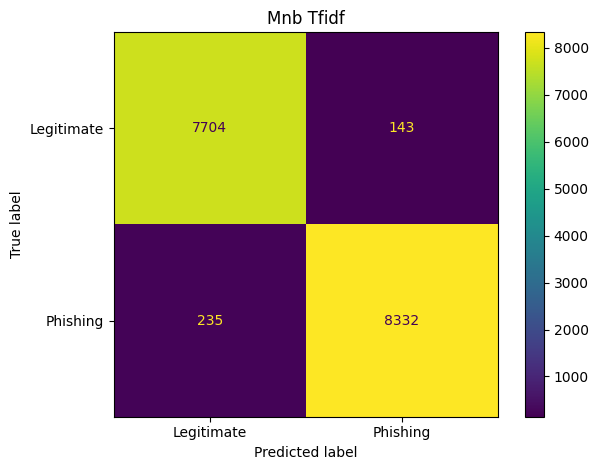

              precision    recall  f1-score   support

  Legitimate     0.9704    0.9818    0.9761      7847
    Phishing     0.9831    0.9726    0.9778      8567

    accuracy                         0.9770     16414
   macro avg     0.9768    0.9772    0.9769     16414
weighted avg     0.9770    0.9770    0.9770     16414

mnb_tfidf {'accuracy': 0.976970878518338, 'precision': 0.9831268436578171, 'recall': 0.9725691607330454, 'f1': 0.9778195047529633, 'training_time_min': 0.29631874163945515}


In [23]:
# MODEL A - Multinomial Naive Bayes (paper's fast/interpretable baseline)
nb_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=MAX_TFIDF_FEATURES, stop_words='english')),
    ('clf', MultinomialNB()),
])
nb_pipeline, nb_metrics, nb_pred, nb_cm = train_and_eval('mnb_tfidf', nb_pipeline, train_df, test_df)

## 10. MODEL B - Random Forest, 100 trees (TF-IDF)

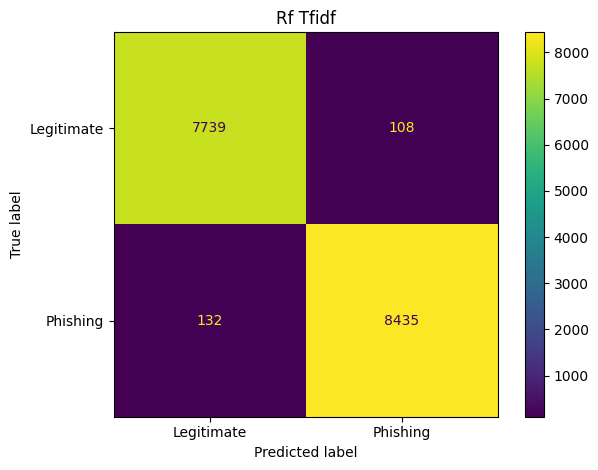

              precision    recall  f1-score   support

  Legitimate     0.9832    0.9862    0.9847      7847
    Phishing     0.9874    0.9846    0.9860      8567

    accuracy                         0.9854     16414
   macro avg     0.9853    0.9854    0.9854     16414
weighted avg     0.9854    0.9854    0.9854     16414

rf_tfidf {'accuracy': 0.9853783355671988, 'precision': 0.9873580709352686, 'recall': 0.9845920392202638, 'f1': 0.9859731151373465, 'training_time_min': 2.6492414355278013}


In [24]:
# MODEL B - Random Forest, 100 trees (paper's ensemble baseline)
rf_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=MAX_TFIDF_FEATURES, stop_words='english')),
    ('clf', RandomForestClassifier(n_estimators=RF_TREES, random_state=SEED, n_jobs=-1)),
])
rf_pipeline, rf_metrics, rf_pred, rf_cm = train_and_eval('rf_tfidf', rf_pipeline, train_df, test_df)

## 11. MODEL C - Linear-kernel SVC (TF-IDF) - the paper's proposed / best model

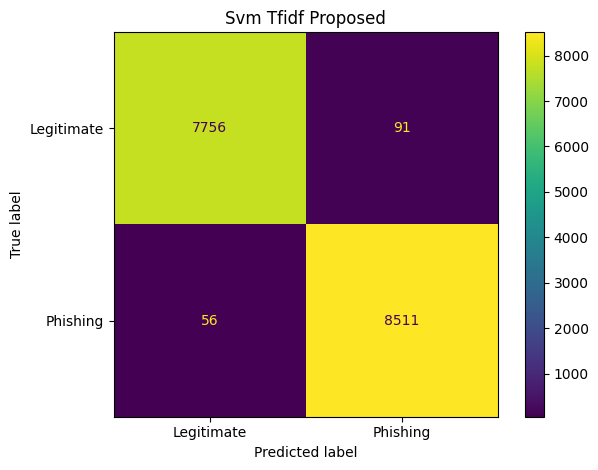

              precision    recall  f1-score   support

  Legitimate     0.9928    0.9884    0.9906      7847
    Phishing     0.9894    0.9935    0.9914      8567

    accuracy                         0.9910     16414
   macro avg     0.9911    0.9909    0.9910     16414
weighted avg     0.9911    0.9910    0.9910     16414

svm_tfidf_proposed {'accuracy': 0.9910442305349092, 'precision': 0.9894210648686352, 'recall': 0.9934632893661726, 'f1': 0.9914380569631313, 'training_time_min': 109.02494475841522}


In [25]:
# MODEL C - Linear-kernel SVC with TF-IDF (the paper's best/"proposed" model)
svm_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=MAX_TFIDF_FEATURES, stop_words='english')),
    ('clf', SVC(kernel='linear', probability=True, random_state=SEED)),
])
svm_pipeline, svm_metrics, svm_pred, svm_cm = train_and_eval('svm_tfidf_proposed', svm_pipeline, train_df, test_df)

## 12. Optional ablation: TF-IDF vs Word2Vec (reproduces the paper's key preprocessing finding)

In [26]:
# Optional ablation: TF-IDF vs Word2Vec-averaged vectors, feeding the same SVM.
# The paper reports TF-IDF clearly beating Word2Vec (F1 0.99 vs 0.83). This block is
# OFF by default (RUN_WORD2VEC_ABLATION=False) because it adds a gensim training pass;
# switch it on to reproduce that specific finding.
if RUN_WORD2VEC_ABLATION:
    from gensim.models import Word2Vec

    tokenized = train_df['text'].str.split().tolist()
    w2v = Word2Vec(sentences=tokenized, vector_size=100, window=5, min_count=2, workers=4, seed=SEED)

    def doc_vector(tokens, model, dim=100):
        vecs = [model.wv[t] for t in tokens if t in model.wv]
        return np.mean(vecs, axis=0) if vecs else np.zeros(dim)

    X_train_w2v = np.vstack([doc_vector(t, w2v) for t in train_df['text'].str.split()])
    X_test_w2v = np.vstack([doc_vector(t, w2v) for t in test_df['text'].str.split()])
    svm_w2v = SVC(kernel='linear', random_state=SEED)
    svm_w2v.fit(X_train_w2v, train_df['label'])
    w2v_pred = svm_w2v.predict(X_test_w2v)
    w2v_metrics = metrics_from_preds(test_df['label'], w2v_pred)
    with open(RESULTS_DIR / 'svm_word2vec_metrics.json', 'w') as f:
        json.dump(w2v_metrics, f, indent=2)
    print('SVM + Word2Vec:', w2v_metrics)
    print('SVM + TF-IDF  :', svm_metrics)
    print('This should reproduce the paper\'s qualitative finding that tf-idf > word2vec.')

## 13. Direct comparison: our three models, same dataset and split

In [27]:
comparison = pd.DataFrame([
    {'model': 'Multinomial NB (TF-IDF)', **nb_metrics},
    {'model': 'Random Forest (TF-IDF)', **rf_metrics},
    {'model': 'Linear SVM (TF-IDF) - proposed', **svm_metrics},
])
for metric in ['accuracy', 'precision', 'recall', 'f1']:
    comparison[metric] = comparison[metric].astype(float)
display(comparison)
comparison.to_csv(RESULTS_DIR / 'comparison_ours.csv', index=False)

,model,accuracy,precision,recall,f1,training_time_min
0,Multinomial NB (TF-IDF),0.976971,0.983127,0.972569,0.977820,0.296319
1,Random Forest (TF-IDF),0.985378,0.987358,0.984592,0.985973,2.649241
2,Linear SVM (TF-IDF) - proposed,0.991044,0.989421,0.993463,0.991438,109.024945


## 14. Compare our results with the values reported in the 2024 paper (Table 2)

In [28]:
# Literature values reported in Table 2 of the paper for the merged (Enron+Ling+CEAS+
# Nazario+Nigerian Fraud+SpamAssassin) dataset, tf-idf preprocessing:
#   SVC (proposed): accuracy 0.991, precision 0.99, recall 0.99, f1 0.99
#   Multinomial NB: accuracy 0.978, precision 0.97, recall 0.99, f1 0.98
#   Random Forest : accuracy 0.984, precision 0.98, recall 0.99, f1 0.98
paper = {
    'svm_tfidf_proposed': {'accuracy': 0.991, 'precision': 0.99, 'recall': 0.99, 'f1': 0.99},
    'mnb_tfidf': {'accuracy': 0.978, 'precision': 0.97, 'recall': 0.99, 'f1': 0.98},
    'rf_tfidf': {'accuracy': 0.984, 'precision': 0.98, 'recall': 0.99, 'f1': 0.98},
}
ours = {'svm_tfidf_proposed': svm_metrics, 'mnb_tfidf': nb_metrics, 'rf_tfidf': rf_metrics}
paper_vs = []
for model_key, paper_vals in paper.items():
    for metric in ['accuracy', 'precision', 'recall', 'f1']:
        paper_vs.append({
            'model': model_key, 'metric': metric,
            'paper_2024': paper_vals[metric],
            'our_value': ours[model_key][metric],
            'difference_ours_minus_paper': ours[model_key][metric] - paper_vals[metric],
        })
paper_vs_df = pd.DataFrame(paper_vs)
display(paper_vs_df)
paper_vs_df.to_csv(RESULTS_DIR / 'paper_vs_ours.csv', index=False)

,model,metric,paper_2024,our_value,difference_ours_minus_paper
0,svm_tfidf_proposed,accuracy,0.991,0.991044,0.000044
1,svm_tfidf_proposed,precision,0.990,0.989421,-0.000579
2,svm_tfidf_proposed,recall,0.990,0.993463,0.003463
3,svm_tfidf_proposed,f1,0.990,0.991438,0.001438
4,mnb_tfidf,accuracy,0.978,0.976971,-0.001029
5,mnb_tfidf,precision,0.970,0.983127,0.013127
6,mnb_tfidf,recall,0.990,0.972569,-0.017431
7,mnb_tfidf,f1,0.980,0.977820,-0.002180
8,rf_tfidf,accuracy,0.984,0.985378,0.001378
9,rf_tfidf,precision,0.980,0.987358,0.007358


## 15. Paired significance check: McNemar test (SVM vs Naive Bayes)

In [29]:
# Paired significance check: McNemar test, SVM (proposed) vs Multinomial NB (baseline).
y_true = test_df['label'].to_numpy()
svm_wrong_nb_correct = int(np.sum((svm_pred != y_true) & (nb_pred == y_true)))
nb_wrong_svm_correct = int(np.sum((nb_pred != y_true) & (svm_pred == y_true)))
table = [[0, nb_wrong_svm_correct], [svm_wrong_nb_correct, 0]]
res = mcnemar(table, exact=True)
mcnemar_out = {
    'nb_wrong_svm_correct': nb_wrong_svm_correct,
    'svm_wrong_nb_correct': svm_wrong_nb_correct,
    'pvalue': float(res.pvalue),
}
print(mcnemar_out)
with open(RESULTS_DIR / 'mcnemar_result.json', 'w') as f:
    json.dump(mcnemar_out, f, indent=2)

{'nb_wrong_svm_correct': 291, 'svm_wrong_nb_correct': 60, 'pvalue': 1.6278097212691965e-37}


## 16. Error analysis: false negatives and false positives

In [30]:
def error_summary(name, pred):
    temp = test_df.copy()
    temp['prediction'] = pred
    fn = temp[(temp.label == 1) & (temp.prediction == 0)].copy()
    fp = temp[(temp.label == 0) & (temp.prediction == 1)].copy()
    print(name, 'false negatives:', len(fn), 'false positives:', len(fp))
    display(fn.head(5))
    display(fp.head(5))
    fn.to_csv(RESULTS_DIR / f'{name}_false_negatives.csv', index=False)
    fp.to_csv(RESULTS_DIR / f'{name}_false_positives.csv', index=False)

error_summary('svm_tfidf_proposed', svm_pred)
error_summary('mnb_tfidf', nb_pred)

svm_tfidf_proposed false negatives: 56 false positives: 91


,text,label,prediction
942,dscfahyeircomnet hello two sorry catherine wri...,1,0
959,enlarge bre 4 sts unsubscribe,1,0
1032,nawty locals area pdi e x local singles inside...,1,0
1139,post secondary certificates sale still uniover...,1,0
1956,virtual conference technology showcase cm cros...,1,0


,text,label,prediction
65,massimiliano marini vualinuxtimeit hint might ...,0,1
77,diveintomark rssfeedsspamassassintaintorg url ...,0,1
199,joseph brennan vupzesmcolumbiaedu worked well ...,0,1
213,important video announcement important video a...,0,1
451,look look found jobsearch monster com thought ...,0,1


mnb_tfidf false negatives: 235 false positives: 143


,text,label,prediction
16,delivery status notification failure automatic...,1,0
17,international calls 33 cents per minute subscr...,1,0
250,photoshop windows office cheap martian wadswor...,1,0
351,meniscus minuet occurred minuet occurred minue...,1,0
377,epost360cncom ou wei lighting nights lightenin...,1,0


,text,label,prediction
25,pace university evppaceedu messages quarantine...,0,1
39,borders rewards sqxwkcdebordersstorescom borde...,0,1
77,diveintomark rssfeedsspamassassintaintorg url ...,0,1
81,gnc hijemailgnccom check new products plus sav...,0,1
213,important video announcement important video a...,0,1


## 17. Model interpretability with LIME (matches the paper's Section 6)

LIME explanation for a phishing-labelled test email:
               06  +0.0085
             nude  +0.0074
       processing  +0.0063
              wed  +0.0061
              aug  +0.0056
            movie  +0.0052
          dowload  +0.0042
              url  -0.0041
             0700  +0.0032
             2008  -0.0028


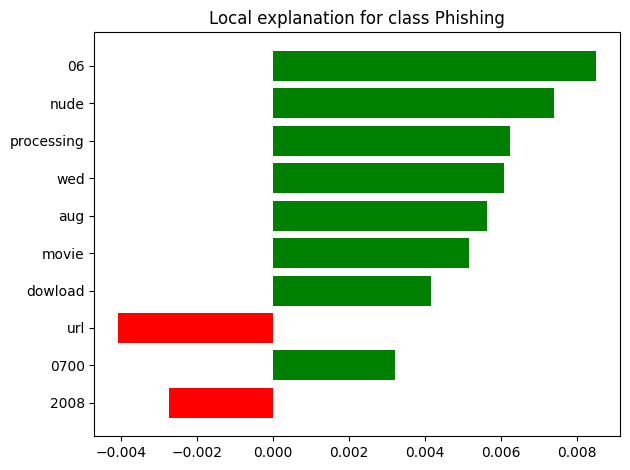

In [31]:
# Explainable AI: LIME, matching the paper's use of Local Interpretable Model-Agnostic
# Explanations to show which words drove a single prediction (Section 6 of the paper).
from lime.lime_text import LimeTextExplainer

explainer = LimeTextExplainer(class_names=['Legitimate', 'Phishing'])
sample_idx = test_df[test_df.label == 1].index[0]
sample_text = test_df.loc[sample_idx, 'text']

def predict_proba_fn(texts):
    return svm_pipeline.predict_proba(texts)

exp = explainer.explain_instance(sample_text, predict_proba_fn, num_features=LIME_NUM_FEATURES)
print('LIME explanation for a phishing-labelled test email:')
for word, weight in exp.as_list():
    print(f'  {word:>15s}  {weight:+.4f}')
exp.save_to_file(str(RESULTS_DIR / 'lime_explanation_example.html'))
fig = exp.as_pyplot_figure()
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'lime_explanation_example.png', dpi=300)
plt.show()

## 18. Final summary and ZIP for supervisor

In [32]:
summary_lines = []
summary_lines.append('2024 Phishing Framework Reproduction - Controlled Comparison')
summary_lines.append(f'Dataset final records: {len(df)} | train={len(train_df)} test={len(test_df)}')
summary_lines.append('Multinomial NB (TF-IDF): ' + json.dumps(nb_metrics))
summary_lines.append('Random Forest (TF-IDF): ' + json.dumps(rf_metrics))
summary_lines.append('Linear SVM (TF-IDF, proposed): ' + json.dumps(svm_metrics))
summary_lines.append('McNemar (SVM vs NB): ' + json.dumps(mcnemar_out))
summary_lines.append('Paper literature values: ' + json.dumps(paper))
(RESULTS_DIR / 'FINAL_RESULT_SUMMARY.txt').write_text('\n'.join(summary_lines))
print('\n'.join(summary_lines))

zip_path = shutil.make_archive('/content/phishing_2024_project_results', 'zip', root_dir=str(PROJECT_DIR))
print('Download this ZIP:', zip_path)

2024 Phishing Framework Reproduction - Controlled Comparison
Dataset final records: 82068 | train=65654 test=16414
Multinomial NB (TF-IDF): {"accuracy": 0.976970878518338, "precision": 0.9831268436578171, "recall": 0.9725691607330454, "f1": 0.9778195047529633, "training_time_min": 0.29631874163945515}
Random Forest (TF-IDF): {"accuracy": 0.9853783355671988, "precision": 0.9873580709352686, "recall": 0.9845920392202638, "f1": 0.9859731151373465, "training_time_min": 2.6492414355278013}
Linear SVM (TF-IDF, proposed): {"accuracy": 0.9910442305349092, "precision": 0.9894210648686352, "recall": 0.9934632893661726, "f1": 0.9914380569631313, "training_time_min": 109.02494475841522}
McNemar (SVM vs NB): {"nb_wrong_svm_correct": 291, "svm_wrong_nb_correct": 60, "pvalue": 1.6278097212691965e-37}
Paper literature values: {"svm_tfidf_proposed": {"accuracy": 0.991, "precision": 0.99, "recall": 0.99, "f1": 0.99}, "mnb_tfidf": {"accuracy": 0.978, "precision": 0.97, "recall": 0.99, "f1": 0.98}, "rf_tf